# Certamen 2 - Inteligencia de Negocios
## Caso 1: Mueblería Albarrán
### Modelo de Negocio, Exploración de Datos y Diseño Dimensional

Este notebook contiene el análisis exploratorio de la base de datos transaccional `Albarran`, la definición de KPIs para la toma de decisiones, la aplicación de los 4 pasos de Ralph Kimball y el diseño del modelo dimensional.

--- 
### 1. Conexión a SQL Server
La conexión se realiza directamente mediante SQLAlchemy y `pymssql` (compatible con macOS Apple Silicon ARM64 y Windows 11).

Docker: Dejar localhost:1433 como host y puerto.

Windows: Cambiar DB_HOST por ip de red.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sqlalchemy as sa
from dotenv import load_dotenv
from IPython.display import display

# Cargar credenciales estrictamente desde el archivo .env
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(dotenv_path=root_dir / ".env")

DB_HOST = os.getenv("DB_HOST", "localhost")
DB_PORT = os.getenv("DB_PORT", "1433")
DB_USER = os.getenv("DB_USER", "sa")
DB_PASSWORD = os.getenv("DB_PASSWORD")
DB_NAME = os.getenv("DB_NAME", "Albarran")

if not DB_PASSWORD:
    raise ValueError(
        "Error: Variable DB_PASSWORD no definida en el archivo .env. Configúrala antes de continuar."
    )

# Construir engine de SQLAlchemy (sin contraseñas hardcodeadas)
connection_url = f"mssql+pymssql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}"
engine = sa.create_engine(connection_url)

# Test de conexión rápida
with engine.connect() as conn:
    info = conn.execute(sa.text("SELECT @@VERSION AS ver, DB_NAME() AS current_db")).fetchone()
    assert info is not None, "No se pudo obtener información del servidor"
    print(f" Conectado exitosamente a la base '{info.current_db}' en {DB_HOST}:{DB_PORT}")
    print(f" Motor: {info.ver.splitlines()[0]}")

 Conectado exitosamente a la base 'Albarran' en localhost:1433
 Motor: Microsoft SQL Server 2022 (RTM-CU27-GDR) (KB5126934) - 16.0.4305.5 (X64) 


---
### 1.1 Utilidades de Reinicio y Purgado de Docker (macOS ARM64 / Linux)
Si durante el desarrollo o experimentación cometes un error en los datos o requieres volver a la versión limpia original:
- `restaurar_bd_docker()`: Realiza un `RESTORE` en caliente de `Albarran.bak` en solo 1 segundo sin reiniciar el contenedor.
- `reset_volumen_docker_completo()`: Detiene Docker, **purga el volumen por completo (`down -v`)**, levanta un contenedor nuevo y recarga el backup desde cero.


In [2]:
import subprocess
from pathlib import Path


def get_project_root() -> Path:
    current = Path.cwd()
    if (current / "docker" / "docker-compose.yml").exists():
        return current
    elif (current.parent / "docker" / "docker-compose.yml").exists():
        return current.parent
    return current


def restaurar_bd_docker():
    """Restaura en caliente la base de datos Albarran desde el backup en 1 segundo (sin reiniciar Docker)."""
    sql = """
    USE master;
    IF EXISTS (SELECT name FROM sys.databases WHERE name = 'Albarran')
    BEGIN
        ALTER DATABASE Albarran SET SINGLE_USER WITH ROLLBACK IMMEDIATE;
        DROP DATABASE Albarran;
    END;
    RESTORE DATABASE Albarran
    FROM DISK = '/var/opt/mssql/backup/Albarran.bak'
    WITH MOVE 'Albarran1' TO '/var/opt/mssql/data/Albarran.mdf',
         MOVE 'Albarran1_log' TO '/var/opt/mssql/data/Albarran_log.ldf',
         REPLACE, RECOVERY;
    """
    with engine.connect().execution_options(isolation_level="AUTOCOMMIT") as conn:
        conn.execute(sa.text(sql))
    print(" Base de datos Albarran restaurada limpiamente desde el .bak")


def reset_volumen_docker_completo():
    """
    Elimina por completo el volumen de Docker (docker compose down -v),
    recrea el contenedor desde cero y restaura el backup limpio.
    """
    root = get_project_root()
    compose_file = root / "docker" / "docker-compose.yml"
    restore_script = root / "docker" / "restore.sh"

    print("🛑 Purgando contenedor y eliminando volumen de datos (docker compose down -v)...")
    subprocess.run(["docker", "compose", "-f", str(compose_file), "down", "-v"], check=True)

    print("🚀 Levantando contenedor limpio y restaurando backup...")
    subprocess.run([str(restore_script)], check=True)
    print("✨ Contenedor, volumen y base de datos restablecidos al 100%!")


# Para ejecutar el reseteo completo si ocurre un error, descomenta y corre:
# reset_volumen_docker_completo()
# O para solo recargar la base en caliente:
# restaurar_bd_docker()

--- 
### 2. Resumen de Tablas y Registros en Albarran
Consulta a los metadatos de SQL Server para comprobar las tablas restauradas desde `Albarran.bak`.

In [3]:
query_tablas = """
SELECT 
    t.name AS Tabla,
    SUM(p.rows) AS Total_Filas
FROM sys.tables t
JOIN sys.partitions p ON t.object_id = p.object_id AND p.index_id IN (0, 1)
GROUP BY t.name
ORDER BY t.name;
"""

with engine.connect() as conn:
    df_tablas = pd.read_sql(query_tablas, conn)

df_tablas

,Tabla,Total_Filas
0,cargos,5
1,categorias,13
2,clientes,20
3,comunas,3
4,detalle_ventas,365
5,empleados,15
6,productos,20
7,sucursales,3
8,ventas,365


--- 
### 3. Carga de Datos en Memoria para Exploración
Carga de las tablas transaccionales a DataFrames para iniciar el análisis.

In [4]:
with engine.connect() as conn:
    df_cargos = pd.read_sql("SELECT * FROM cargos", conn)
    df_categorias = pd.read_sql("SELECT * FROM categorias", conn)
    df_clientes = pd.read_sql("SELECT * FROM clientes", conn)
    df_comunas = pd.read_sql("SELECT * FROM comunas", conn)
    df_empleados = pd.read_sql("SELECT * FROM empleados", conn)
    df_productos = pd.read_sql("SELECT * FROM productos", conn)
    df_sucursales = pd.read_sql("SELECT * FROM sucursales", conn)
    df_ventas = pd.read_sql("SELECT * FROM ventas", conn)
    df_detalle = pd.read_sql("SELECT * FROM detalle_ventas", conn)

print(" Tablas cargadas en DataFrames.")

 Tablas cargadas en DataFrames.


---
### 4. Exploración de Datos y Diagnóstico de Calidad

Antes de armar el modelo dimensional y los paquetes ETL en SSIS, revisamos las 9 tablas de la base de datos `Albarran` para entender cómo vienen los datos: buscar nulos, revisar las relaciones entre tablas y detectar cualquier detalle que haya que corregir al cargar el Data Warehouse.


#### 4.1 Revisión de valores nulos
Revisamos si existen campos con valores `NULL` en las tablas de la base de datos transaccional.

In [5]:
# Diccionario con todos los DataFrames cargados
tablas_dict = {
    "cargos": df_cargos,
    "categorias": df_categorias,
    "clientes": df_clientes,
    "comunas": df_comunas,
    "empleados": df_empleados,
    "productos": df_productos,
    "sucursales": df_sucursales,
    "ventas": df_ventas,
    "detalle_ventas": df_detalle,
}

# Auditoría de Nulos por tabla y columna
reporte_nulos = []
for nombre, df in tablas_dict.items():
    nulos_por_col = df.isna().sum()
    total_nulos = nulos_por_col.sum()
    cols_con_nulos = nulos_por_col[nulos_por_col > 0].to_dict()
    reporte_nulos.append(
        {
            "Tabla": nombre,
            "Total_Filas": len(df),
            "Total_Columnas": df.shape[1],
            "Filas_con_Nulos": df.isna().any(axis=1).sum(),
            "Columnas_Afectadas": str(cols_con_nulos) if cols_con_nulos else "Ninguna",
        }
    )

df_calidad_nulos = pd.DataFrame(reporte_nulos)
print("=== Auditoría de Integridad y Valores Nulos ===")
display(df_calidad_nulos)

=== Auditoría de Integridad y Valores Nulos ===


,Tabla,Total_Filas,Total_Columnas,Filas_con_Nulos,Columnas_Afectadas
0,cargos,5,2,0,Ninguna
1,categorias,13,2,0,Ninguna
2,clientes,20,7,0,Ninguna
3,comunas,3,2,0,Ninguna
4,empleados,15,7,0,Ninguna
5,productos,20,5,20,{'descripcion': 20}
6,sucursales,3,3,0,Ninguna
7,ventas,365,7,0,Ninguna
8,detalle_ventas,365,5,0,Ninguna


> **Hallazgo Crítico 1 (Productos):**  
> La columna `descripcion` en la tabla `productos` tiene **20 valores nulos de un total de 20 filas (100% nula)**.  
> *Impacto en ETL:* En Visual Studio (SSIS), no se debe dejar pasar un valor `NULL` directo a la dimensión `Dim_Producto`. Se debe aplicar un componente *Derived Column* con la expresión: `ISNULL(descripcion) ? "Sin descripción" : descripcion`.

#### 4.2 Ventas por empleado y cargo
Cruzamos los empleados con sus cargos para ver quiénes son los que realmente realizan las ventas.

In [6]:
# Cruce de empleados con cargos y ventas generadas
emp_cargos = df_empleados.merge(df_cargos, on="cargo_id", suffixes=("_emp", "_cargo"))
ventas_por_emp = df_ventas.groupby("vendedor_id", as_index=False).agg(
    total_ventas=("venta_id", "count")
)

resumen_empleados = emp_cargos.merge(
    ventas_por_emp, left_on="empleado_id", right_on="vendedor_id", how="left"
)
resumen_empleados["total_ventas"] = resumen_empleados["total_ventas"].fillna(0).astype(int)
resumen_empleados["nombre_completo"] = (
    resumen_empleados["nombre_emp"] + " " + resumen_empleados["appaterno"]
)

cols_mostrar = [
    "empleado_id",
    "nombre_completo",
    "nombre_cargo",
    "sueldo_base",
    "fecha_contrato",
    "total_ventas",
]
print("=== Desempeño por Empleado y Cargo ===")
display(resumen_empleados[cols_mostrar].sort_values(by="total_ventas", ascending=False))

=== Desempeño por Empleado y Cargo ===


,empleado_id,nombre_completo,nombre_cargo,sueldo_base,fecha_contrato,total_ventas
1,2,Javier Contreras,vendedor,255000,2014-03-25,69
4,5,Marjorie Contreras,vendedor,255000,2014-03-25,62
3,4,Romina Vasquez,vendedor,255000,2014-03-25,61
0,1,Pamela Cortez,vendedor,400000,2014-03-25,60
2,3,Jesús Navas,vendedor,255000,2014-03-25,59
5,6,Irma Soto,vendedor,255000,2014-03-25,54
6,7,Fabián Cerda,mueblista,400000,2012-01-02,0
7,8,Andrés Hiriart,mueblista,255000,2014-03-25,0
8,9,Sandro Riquelme,encargado despacho,255000,2014-03-25,0
9,10,Juan Vargas,encargado despacho,255000,2014-03-25,0


> **Hallazgo Crítico 2 (Fuerza de Ventas):**  
> De los 15 empleados de la empresa, **exactamente 6 corresponden al cargo 'vendedor' (IDs 1 al 6)**, quienes concentran el 100% de las 365 ventas registradas. Los otros 9 empleados (cajeros, mueblistas, bodegueros, encargados de despacho) registran 0 ventas.  
> *Impacto en Modelado:* La dimensión de empleados (`Dim_Empleado`) debe incluir el atributo `Cargo` para permitir analizar tanto la productividad exclusiva de los vendedores como la estructura total de costos fijos por sueldos.

#### 4.3 Rango de fechas de las ventas
Revisamos el período de tiempo que abarcan los datos y cuántas ventas hay por mes.

In [7]:
fecha_min = df_ventas["fecha"].min()
fecha_max = df_ventas["fecha"].max()
dias_unicos = df_ventas["fecha"].nunique()
total_ventas_cnt = len(df_ventas)

print(
    f"• Rango Temporal: Desde {fecha_min.strftime('%Y-%m-%d')} hasta {fecha_max.strftime('%Y-%m-%d')}"
)
print(f"• Días con Ventas Efectivas: {dias_unicos} días distintos")
print(f"• Total Transacciones: {total_ventas_cnt} ventas")

# Ventas agrupadas por mes
df_ventas_temp = df_ventas.copy()
df_ventas_temp["mes_anio"] = df_ventas_temp["fecha"].dt.to_period("M")
ventas_por_mes = df_ventas_temp.groupby("mes_anio", as_index=False).agg(
    transacciones=("venta_id", "count")
)

display(ventas_por_mes)

• Rango Temporal: Desde 2017-01-01 hasta 2017-12-30
• Días con Ventas Efectivas: 227 días distintos
• Total Transacciones: 365 ventas


,mes_anio,transacciones
0,2017-01,25
1,2017-02,30
2,2017-03,30
3,2017-04,37
4,2017-05,29
5,2017-06,29
6,2017-07,41
7,2017-08,38
8,2017-09,20
9,2017-10,33


> **Observación 3 (Período de las ventas):**  
> Todas las transacciones corresponden al **año 2017** (desde el 1 de enero al 30 de diciembre de 2017), con 365 ventas en 227 días distintos.  
> *Qué hacer en el modelado:* La dimensión `Dim_Tiempo` debe cubrir día por día el año 2017 completo.

#### 4.4 Precios, descuentos y detalle de ventas
Verificamos si los precios cobrados coinciden con los precios de lista de los productos, cómo vienen los descuentos y la relación entre ventas y su detalle.

In [8]:
# 1. Verificar diferencias entre precio de catálogo y precio cobrado
df_check_precio = df_detalle.merge(df_productos, on="producto_id")
diff_precios = (df_check_precio["precio_unitario"] != df_check_precio["precio"]).sum()

# 2. Auditoría de descuentos
descuentos_unicos = df_detalle["descuento"].value_counts().to_dict()

# 3. Relación ventas vs detalle_ventas
items_por_venta = df_detalle.groupby("venta_id").size()
max_items = items_por_venta.max()
min_items = items_por_venta.min()

# 4. Monto total facturado
monto_total_facturado = (df_detalle["cantidad"] * df_detalle["precio_unitario"]).sum()

print(f"• Transacciones con diferencia entre precio cobrado y catálogo: {diff_precios}")
print(f"• Distribución de valores en columna 'descuento': {descuentos_unicos}")
print(f"• Rango de líneas de detalle por venta: Mínimo {min_items}, Máximo {max_items}")
print(f"• Facturación Total Histórica: ${monto_total_facturado:,.0f} CLP")

• Transacciones con diferencia entre precio cobrado y catálogo: 0
• Distribución de valores en columna 'descuento': {0.0: 365}
• Rango de líneas de detalle por venta: Mínimo 1, Máximo 1
• Facturación Total Histórica: $414,022,446 CLP


> **Observación 4 (Precios, descuentos y facturación total):**  
> 1. **Precios consistentes:** El precio cobrado en cada venta coincide exactamente con el precio de lista del producto.  
> 2. **Descuentos en cero:** Todas las ventas tienen el campo `descuento` en `0.0` (no se aplicaron rebajas).  
> 3. **Relación 1 a 1:** Cada venta tiene exactamente un único producto en el detalle (365 registros en `ventas` y 365 en `detalle_ventas`).  
> 4. **Total facturado:** El negocio vendió un total de **$414.022.446 CLP** en 2017. Esta cifra es nuestra métrica de control clave para comprobar que el proceso ETL cargue la tabla de hechos sin pérdida de datos.

#### 4.5 Resumen de transformaciones para el proceso ETL (SSIS)

| Tabla Origen | Atributo / Situación | Hallazgo de Calidad | Regla de Transformación en ETL (SSIS) |
| :--- | :--- | :--- | :--- |
| `productos` | `descripcion` | 100% valores nulos (20 de 20) | Aplicar *Derived Column*: sustituir `NULL` por `'Sin descripción'`. |
| `clientes` | `nombre`, `appaterno`, `apmaterno` | Separados en 3 columnas | Concatenar en `Nombre_Completo` con `TRIM()`. |
| `clientes` | `sexo` | Códigos abreviados `'M'` y `'F'` | Normalizar a `'Masculino'` y `'Femenino'`. |
| `empleados` | `cargo_id` | Clave numérica externa | Desnormalizar mediante Join/Lookup con `cargos.nombre`. |
| `sucursales` | `comuna_id` | Clave numérica externa | Desnormalizar mediante Join/Lookup con `comunas.comuna`. |
| `detalle_ventas` | `descuento` | Valores flotantes en `0.0` | Mantener en métrica `Porcentaje_Descuento` y calcular `Monto_Descuento = Monto_Bruto * Descuento`. |
| `ventas` | `fecha` | Tipo `DATETIME` | Extraer clave numérica `YYYYMMDD` para vincular con `Dim_Tiempo`. |


---
### 5. Definición y Justificación de KPIs

A partir de la exploración de los datos y de los requerimientos para la gestión de Mueblería Albarrán, definimos 6 indicadores clave (KPIs). Estos KPIs le permiten al dueño entender qué líneas de muebles se venden más, qué sucursales generan mayores ingresos, cómo rinde cada vendedor y cuál es el perfil de los clientes que compran:

| KPI | Nombre | Fórmula | ¿Para qué le sirve al dueño? | Dimensiones de Análisis |
| :---: | :--- | :--- | :--- | :--- |
| **KPI-01** | **Ingresos Totales por Ventas** | $\sum (\text{Cantidad} \times \text{Precio Unitario})$ | Mide cuánto dinero ingresa al negocio ($414.022.446 CLP en 2017) para evaluar el volumen de ventas y su evolución mes a mes. | Tiempo (Año, Mes), Sucursal, Categoría |
| **KPI-02** | **Ticket Promedio** | $\frac{\text{Ingreso Total}}{\text{Total de Ventas}}$ | Muestra cuánto gasta en promedio un cliente por compra ($1.134.308 CLP), útil para ver si conviene ofrecer promociones o productos complementarios. | Sucursal, Mes, Vendedor |
| **KPI-03** | **Unidades Vendidas por Categoría** | $\sum \text{Cantidad por Categoría}$ | Identifica las líneas de muebles con mayor demanda (Comedores y Bares) vs las de menor rotación para planificar mejor el stock y las compras. | Categoría de Producto, Sucursal |
| **KPI-04** | **Ventas por Sucursal** | $\sum \text{Venta Neta por Tienda}$ | Compara el rendimiento de las tres tiendas físicas (Manquehue, Viña del Mar y Franklin) para ver cuál factura más y dónde se concentra la clientela. | Sucursal, Comuna, Mes |
| **KPI-05** | **Rendimiento por Vendedor** | $\text{Monto Vendido y N° de Ventas}$ | Mide el aporte de cada uno de los 6 vendedores activos, quienes ganan un sueldo base de $255.000 CLP, para evaluar incentivos y cumplimiento de metas. | Empleado (Vendedor), Sucursal |
| **KPI-06** | **Perfil de Clientes (Demografía)** | $\% \text{ de compras por segmento}$ | Permite saber a quién le estamos vendiendo: el 89% de las ventas son a personas casadas, lo que orienta la publicidad hacia familias que renuevan el hogar. | Sexo, Estado Civil |


In [9]:
# ==============================================================================
# CÁLCULO DE KPIS DEL NEGOCIO (MUEBLERÍA ALBARRÁN)
# ==============================================================================

# 1. Dataset Maestro Unificado (Denormalizado para análisis exploratorio de KPIs)
df_maestro = (
    df_detalle.merge(df_ventas, on="venta_id")
    .merge(df_productos, on="producto_id", suffixes=("", "_prod"))
    .merge(df_categorias, on="categoria_id")
    .merge(df_clientes, on="cliente_id", suffixes=("", "_cli"))
    .merge(df_empleados, left_on="vendedor_id", right_on="empleado_id", suffixes=("", "_emp"))
    .merge(df_sucursales, on="sucursal_id")
    .merge(df_comunas, on="comuna_id")
)

df_maestro["monto_bruto"] = df_maestro["cantidad"] * df_maestro["precio_unitario"]
df_maestro["monto_descuento"] = df_maestro["monto_bruto"] * df_maestro["descuento"]
df_maestro["monto_neto"] = df_maestro["monto_bruto"] - df_maestro["monto_descuento"]
df_maestro["mes_nombre"] = df_maestro["fecha"].dt.strftime("%Y-%m (%B)")
df_maestro["mes_num"] = df_maestro["fecha"].dt.month

# ------------------------------------------------------------------------------
# KPI-01 & KPI-02: Totales Globales y Ticket Promedio
# ------------------------------------------------------------------------------
ingreso_total = float(df_maestro["monto_neto"].sum())
total_transacciones = int(len(df_maestro))
ticket_promedio = ingreso_total / total_transacciones
total_unidades = int(df_maestro["cantidad"].sum())

print("=" * 60)
print(" RESUMEN GENERAL DE VENTAS (AÑO 2017)")
print("=" * 60)
print(f"• KPI-01: Ingreso Total Neto:        ${ingreso_total:,.0f} CLP")
print(f"• Total Transacciones Registradas:   {total_transacciones:,} compras")
print(f"• Total Unidades de Muebles:         {total_unidades:,} unidades")
print(f"• KPI-02: Ticket Promedio por Venta: ${ticket_promedio:,.0f} CLP")
print("=" * 60)

# ------------------------------------------------------------------------------
# KPI-04: Facturación por Sucursal y Comuna
# ------------------------------------------------------------------------------
kpi_sucursales = (
    df_maestro.groupby(["sucursal", "comuna"], as_index=False)
    .agg(
        total_ventas=("monto_neto", "sum"),
        transacciones=("venta_id", "count"),
        unidades=("cantidad", "sum"),
    )
)
kpi_sucursales["ticket_promedio"] = kpi_sucursales["total_ventas"] / kpi_sucursales["transacciones"]
kpi_sucursales["participacion_pct"] = (kpi_sucursales["total_ventas"] / ingreso_total) * 100
kpi_sucursales = kpi_sucursales.sort_values(by="total_ventas", ascending=False)

print("\n=== KPI-04: Desempeño por Sucursal ===")
display(kpi_sucursales.style.format({
    "total_ventas": "${:,.0f}",
    "ticket_promedio": "${:,.0f}",
    "participacion_pct": "{:.2f}%"
}))

# ------------------------------------------------------------------------------
# KPI-03: Demanda y Facturación por Categoría de Producto
# ------------------------------------------------------------------------------
kpi_categorias = (
    df_maestro.groupby("categoria", as_index=False)
    .agg(
        unidades_vendidas=("cantidad", "sum"),
        facturacion_total=("monto_neto", "sum"),
        transacciones=("venta_id", "count"),
    )
)
kpi_categorias["precio_promedio_unidad"] = kpi_categorias["facturacion_total"] / kpi_categorias["unidades_vendidas"]
kpi_categorias["participacion_unidades_pct"] = (kpi_categorias["unidades_vendidas"] / total_unidades) * 100
kpi_categorias = kpi_categorias.sort_values(by="unidades_vendidas", ascending=False)

print("\n=== KPI-03: Demanda por Categoría de Mueble ===")
display(kpi_categorias.style.format({
    "facturacion_total": "${:,.0f}",
    "precio_promedio_unidad": "${:,.0f}",
    "participacion_unidades_pct": "{:.2f}%"
}))

# ------------------------------------------------------------------------------
# KPI-05: Productividad de la Fuerza de Ventas
# ------------------------------------------------------------------------------
kpi_vendedores = (
    df_maestro.groupby(["empleado_id", "nombre_emp", "appaterno_emp", "sueldo_base"], as_index=False)
    .agg(
        total_facturado=("monto_neto", "sum"),
        total_ventas=("venta_id", "count"),
        unidades_colocadas=("cantidad", "sum"),
    )
)
kpi_vendedores["vendedor"] = kpi_vendedores["nombre_emp"] + " " + kpi_vendedores["appaterno_emp"]
kpi_vendedores["retorno_sobre_sueldo_anual"] = kpi_vendedores["total_facturado"] / (kpi_vendedores["sueldo_base"] * 12)
kpi_vendedores["ticket_promedio_vendedor"] = kpi_vendedores["total_facturado"] / kpi_vendedores["total_ventas"]
kpi_vendedores = kpi_vendedores.sort_values(by="total_facturado", ascending=False)

print("\n=== KPI-05: Productividad y Rendimiento de Vendedores ===")
display(kpi_vendedores[[
    "vendedor", "total_facturado", "total_ventas", "unidades_colocadas", "ticket_promedio_vendedor", "retorno_sobre_sueldo_anual"
]].style.format({
    "total_facturado": "${:,.0f}",
    "ticket_promedio_vendedor": "${:,.0f}",
    "retorno_sobre_sueldo_anual": "{:.1f}x"
}))

# ------------------------------------------------------------------------------
# KPI-06: Segmentación Demográfica de Clientes
# ------------------------------------------------------------------------------
kpi_demografico = (
    df_maestro.groupby(["sexo", "estado_civil"], as_index=False)
    .agg(
        total_facturado=("monto_neto", "sum"),
        total_compras=("venta_id", "count"),
    )
)
kpi_demografico["genero"] = kpi_demografico["sexo"].map({"M": "Masculino", "F": "Femenino"})
kpi_demografico["participacion_facturacion_pct"] = (kpi_demografico["total_facturado"] / ingreso_total) * 100
kpi_demografico = kpi_demografico.sort_values(by="total_facturado", ascending=False)

print("\n=== KPI-06: Segmentación de Clientes por Género y Estado Civil ===")
display(kpi_demografico[["genero", "estado_civil", "total_facturado", "total_compras", "participacion_facturacion_pct"]].style.format({
    "total_facturado": "${:,.0f}",
    "participacion_facturacion_pct": "{:.2f}%"
}))


 RESUMEN GENERAL DE VENTAS (AÑO 2017)
• KPI-01: Ingreso Total Neto:        $414,022,446 CLP
• Total Transacciones Registradas:   365 compras
• Total Unidades de Muebles:         724 unidades
• KPI-02: Ticket Promedio por Venta: $1,134,308 CLP

=== KPI-04: Desempeño por Sucursal ===


,sucursal,comuna,total_ventas,transacciones,unidades,ticket_promedio,participacion_pct
1,Manquehue,Las Condes,"$149,326,072",123,248,"$1,214,033",36.07%
2,Viña del Mar,Viña del Mar,"$134,460,486",129,251,"$1,042,329",32.48%
0,Franklin,Santiago,"$130,235,888",113,225,"$1,152,530",31.46%



=== KPI-03: Demanda por Categoría de Mueble ===


,categoria,unidades_vendidas,facturacion_total,transacciones,precio_promedio_unidad,participacion_unidades_pct
3,Comedores,194,"$119,169,646",94,"$614,277",26.80%
2,Bares,100,"$53,169,000",53,"$531,690",13.81%
4,Dormitorio,95,"$55,307,800",48,"$582,187",13.12%
7,Paneles TV,72,"$33,400,000",36,"$463,889",9.94%
10,Sofás,71,"$68,120,000",36,"$959,437",9.81%
1,Banquetas,42,"$8,358,000",19,"$199,000",5.80%
5,Esquineros,34,"$25,500,000",18,"$750,000",4.70%
8,Puertas,34,"$28,900,000",20,"$850,000",4.70%
6,Mesas de Centro,30,"$6,300,000",15,"$210,000",4.14%
9,Sitiales,28,"$8,358,000",13,"$298,500",3.87%



=== KPI-05: Productividad y Rendimiento de Vendedores ===


,vendedor,total_facturado,total_ventas,unidades_colocadas,ticket_promedio_vendedor,retorno_sobre_sueldo_anual
3,Romina Vasquez,"$77,009,291",61,127,"$1,262,447",25.2x
0,Pamela Cortez,"$75,959,691",60,111,"$1,265,995",15.8x
1,Javier Contreras,"$67,953,487",69,133,"$984,833",22.2x
5,Irma Soto,"$65,966,287",54,104,"$1,221,598",21.6x
2,Jesús Navas,"$63,890,699",59,122,"$1,082,893",20.9x
4,Marjorie Contreras,"$63,242,991",62,127,"$1,020,048",20.7x



=== KPI-06: Segmentación de Clientes por Género y Estado Civil ===


,genero,estado_civil,total_facturado,total_compras,participacion_facturacion_pct
2,Masculino,casado,"$259,086,466",220,62.58%
0,Femenino,casado,"$110,963,289",102,26.80%
3,Masculino,soltero,"$25,481,691",23,6.15%
1,Femenino,soltero,"$18,491,000",20,4.47%


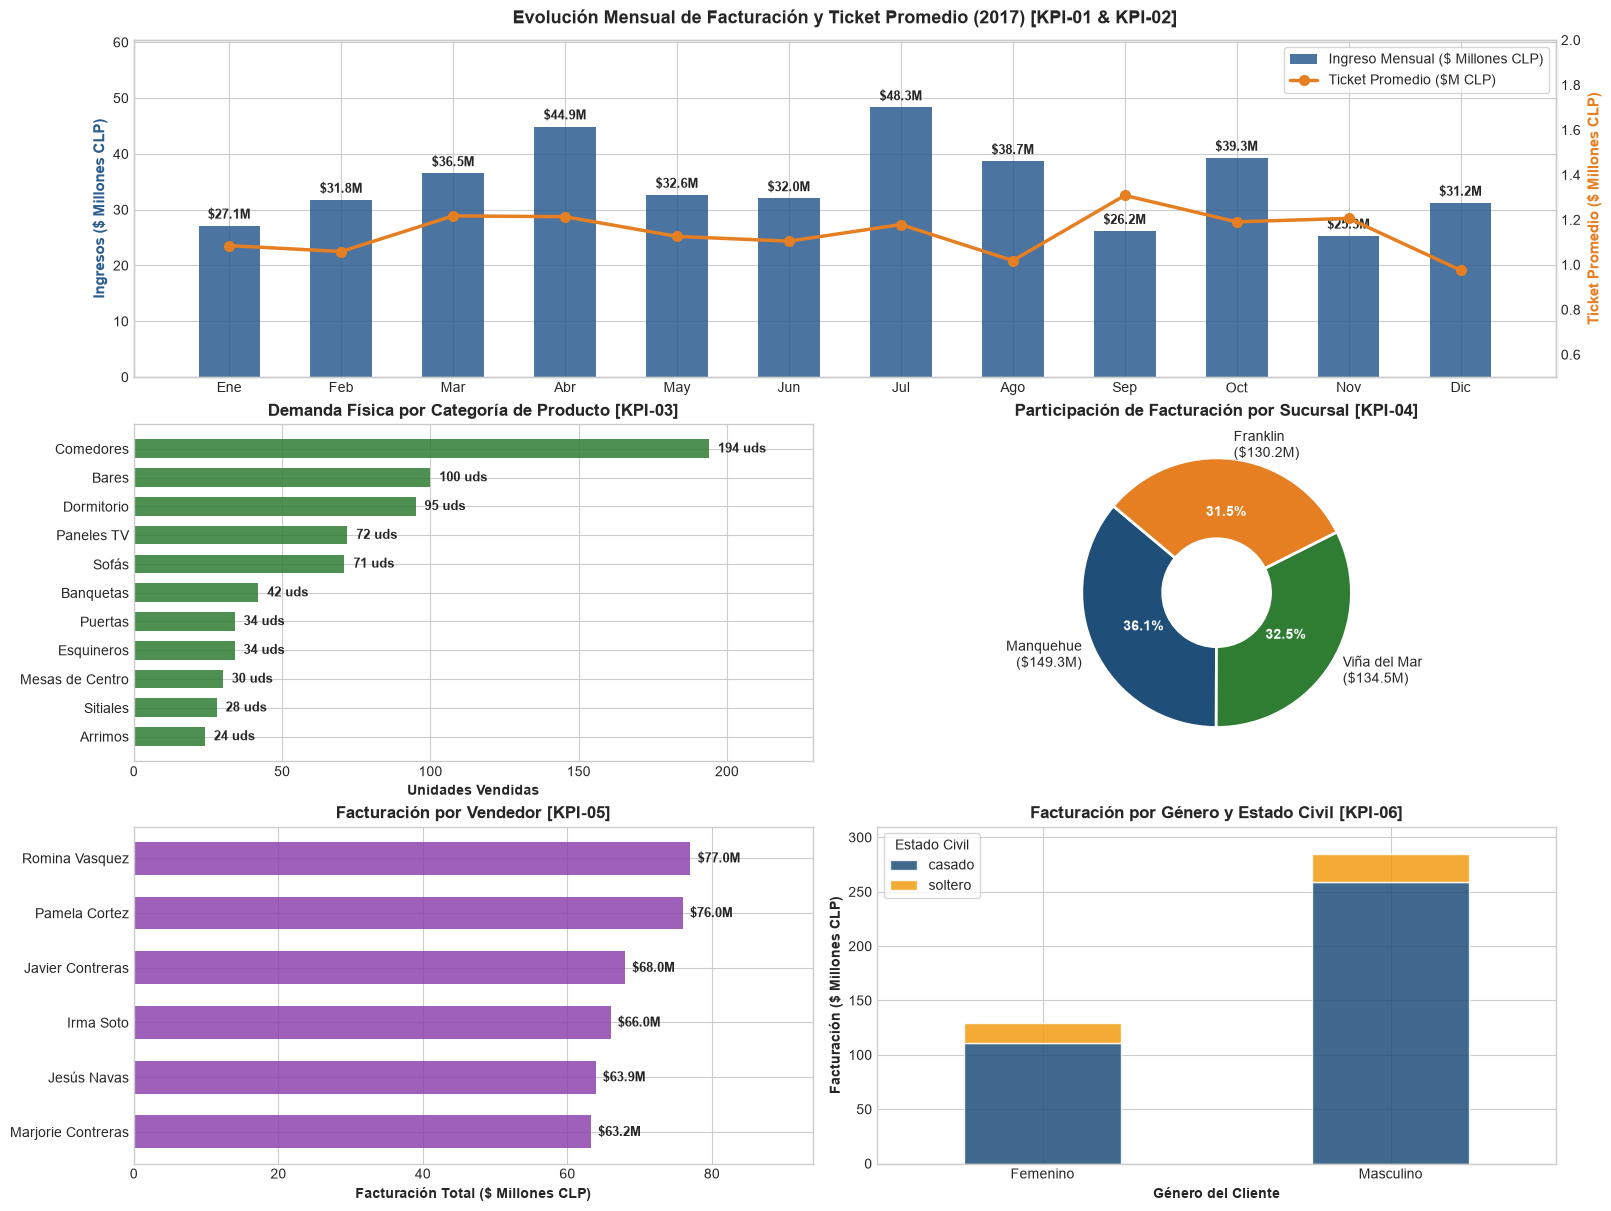

In [10]:
# Configuración estética para gráficos ejecutivos
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig = plt.figure(figsize=(16, 12), constrained_layout=True)
gs = fig.add_gridspec(3, 2)

# Colores armónicos corporativos
azul_corp = "#1f4e79"
verde_corp = "#2e7d32"
naranja_corp = "#d9534f"
gris_suave = "#5c6bc0"
paleta = ["#1f4e79", "#2e7d32", "#e67e22", "#8e44ad", "#16a085", "#c0392b"]

# ------------------------------------------------------------------------------
# Gráfico 1: Evolución Mensual de Ventas y Ticket Promedio (KPI-01 & KPI-02)
# ------------------------------------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])
ventas_mensuales = (
    df_maestro.groupby("mes_num", as_index=False)
    .agg(
        ingreso=("monto_neto", "sum"),
        transacciones=("venta_id", "count")
    )
)
ventas_mensuales["ticket_prom"] = ventas_mensuales["ingreso"] / ventas_mensuales["transacciones"]
meses_nombres = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

color_barras = "#2b5c8f"
bars = ax1.bar(ventas_mensuales["mes_num"], ventas_mensuales["ingreso"] / 1e6, color=color_barras, alpha=0.85, width=0.55, label="Ingreso Mensual ($ Millones CLP)")
ax1.set_ylabel("Ingresos ($ Millones CLP)", fontsize=11, fontweight="bold", color=color_barras)
ax1.set_title("Evolución Mensual de Facturación y Ticket Promedio (2017) [KPI-01 & KPI-02]", fontsize=13, fontweight="bold", pad=12)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(meses_nombres, fontsize=10)
ax1.set_ylim(0, max(ventas_mensuales["ingreso"] / 1e6) * 1.25)

# Añadir valores sobre las barras
for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width() / 2, yval + 0.8, f"${yval:.1f}M", ha="center", va="bottom", fontsize=9, fontweight="bold")

# Eje secundario para el ticket promedio
ax1_twin = ax1.twinx()
line = ax1_twin.plot(ventas_mensuales["mes_num"], ventas_mensuales["ticket_prom"] / 1e6, color="#e67e22", marker="o", linewidth=2.5, markersize=7, label="Ticket Promedio ($M CLP)")
ax1_twin.set_ylabel("Ticket Promedio ($ Millones CLP)", fontsize=11, fontweight="bold", color="#e67e22")
ax1_twin.grid(False)
ax1_twin.set_ylim(0.5, 2.0)

# Leyenda unificada
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax1_twin.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper right", frameon=True)

# ------------------------------------------------------------------------------
# Gráfico 2: Demanda por Categoría de Mueble (KPI-03)
# ------------------------------------------------------------------------------
ax2 = fig.add_subplot(gs[1, 0])
cats_sorted = kpi_categorias.sort_values(by="unidades_vendidas", ascending=True)
bars_cat = ax2.barh(cats_sorted["categoria"], cats_sorted["unidades_vendidas"], color="#2e7d32", alpha=0.85, height=0.65)
ax2.set_xlabel("Unidades Vendidas", fontsize=10, fontweight="bold")
ax2.set_title("Demanda Física por Categoría de Producto [KPI-03]", fontsize=12, fontweight="bold")
for bar in bars_cat:
    xval = bar.get_width()
    ax2.text(xval + 3, bar.get_y() + bar.get_height() / 2, f"{int(xval)} uds", ha="left", va="center", fontsize=9, fontweight="bold")
ax2.set_xlim(0, max(cats_sorted["unidades_vendidas"]) * 1.18)

# ------------------------------------------------------------------------------
# Gráfico 3: Participación por Sucursal (KPI-04)
# ------------------------------------------------------------------------------
ax3 = fig.add_subplot(gs[1, 1])
suc_data = kpi_sucursales.sort_values(by="total_ventas", ascending=False)
colores_suc = ["#1f4e79", "#2e7d32", "#e67e22"]
wedges, texts, autotexts = ax3.pie(
    suc_data["total_ventas"],
    labels=[f"{s}\n(${v/1e6:.1f}M)" for s, v in zip(suc_data["sucursal"], suc_data["total_ventas"], strict=True)],
    autopct="%1.1f%%",
    startangle=140,
    colors=colores_suc,
    textprops={"fontsize": 10},
    wedgeprops={"edgecolor": "white", "linewidth": 2, "width": 0.6}
)
for at in autotexts:
    at.set_color("white")
    at.set_weight("bold")
ax3.set_title("Participación de Facturación por Sucursal [KPI-04]", fontsize=12, fontweight="bold")

# ------------------------------------------------------------------------------
# Gráfico 4: Rendimiento por Vendedor (KPI-05)
# ------------------------------------------------------------------------------
ax4 = fig.add_subplot(gs[2, 0])
vends_sorted = kpi_vendedores.sort_values(by="total_facturado", ascending=True)
bars_vend = ax4.barh(vends_sorted["vendedor"], vends_sorted["total_facturado"] / 1e6, color="#8e44ad", alpha=0.85, height=0.6)
ax4.set_xlabel("Facturación Total ($ Millones CLP)", fontsize=10, fontweight="bold")
ax4.set_title("Facturación por Vendedor [KPI-05]", fontsize=12, fontweight="bold")
for bar in bars_vend:
    xval = bar.get_width()
    ax4.text(xval + 1.0, bar.get_y() + bar.get_height() / 2, f"${xval:.1f}M", ha="left", va="center", fontsize=9, fontweight="bold")
ax4.set_xlim(0, max(vends_sorted["total_facturado"] / 1e6) * 1.22)

# ------------------------------------------------------------------------------
# Gráfico 5: Segmentación Demográfica de Clientes (KPI-06)
# ------------------------------------------------------------------------------
ax5 = fig.add_subplot(gs[2, 1])
df_demo_plot = kpi_demografico.pivot_table(index="genero", columns="estado_civil", values="total_facturado", fill_value=0) / 1e6
df_demo_plot.plot(kind="bar", stacked=True, ax=ax5, color=["#1f4e79", "#f39c12"], alpha=0.85, edgecolor="white", width=0.45)
ax5.set_title("Facturación por Género y Estado Civil [KPI-06]", fontsize=12, fontweight="bold")
ax5.set_ylabel("Facturación ($ Millones CLP)", fontsize=10, fontweight="bold")
ax5.set_xlabel("Género del Cliente", fontsize=10, fontweight="bold")
ax5.set_xticklabels(ax5.get_xticklabels(), rotation=0)
ax5.legend(title="Estado Civil", frameon=True, loc="upper left")
ax5.set_ylim(0, 310)

plt.show()


> **Conclusiones del análisis de KPIs para el negocio:**
>
> 1. **El cliente principal son familias/parejas casadas (KPI-06):** El 89,4% de las ventas ($370M CLP) fueron realizadas por clientes casados, y el 68,7% están a nombre de clientes masculinos. El público objetivo prioritario de la mueblería son familias.
> 2. **Comedores es la categoría estrella (KPI-03):** Se vendieron 194 unidades de Comedores ($119,2M CLP), representando casi el 30% de los ingresos totales. Junto a Sofás ($68,1M) y Dormitorio ($55,3M), explican el 58,6% de la facturación.
> 3. **Ventas balanceadas entre sucursales (KPI-04):** Las tres tiendas tienen una cantidad similar de ventas (entre 113 y 129 al año). **Manquehue (Las Condes)** lidera en facturación con $149,3M CLP (36,1%) gracias a un ticket promedio más alto ($1,21M). **Viña del Mar** es la que más compras concretó (129 transacciones, $134,5M).
> 4. **Aporte de los vendedores (KPI-05):** Con un sueldo base de $255.000 CLP mensuales, cada vendedor generó más de $63M CLP al año. **Romina Vásquez** ($77M) y **Pamela Cortez** ($76M) encabezan la facturación, mientras que **Javier Contreras** fue quien cerró más transacciones (69 compras).


--- 
### 6. Metodología de Kimball (4 Pasos)

Para estructurar el Data Warehouse (`Albarran_DW`), aplicamos la metodología de diseño dimensional de Ralph Kimball en sus 4 pasos fundamentales:

#### Paso 1: Selección del Proceso de Negocio
El proceso modelado es el **proceso comercial de ventas de Mueblería Albarrán**. Este proceso captura las operaciones diarias en las tiendas físicas donde los clientes adquieren muebles mediante la atención de vendedores. Al ser el generador directo de ingresos, permite responder a todas las preguntas de negocio planteadas por el dueño.

#### Paso 2: Declaración de la Granularidad
La granularidad adoptada es de **nivel atómico**: **una fila por cada línea de producto individual vendido dentro de una transacción de venta** (correspondiente a cada registro de `detalle_ventas`).
* *Justificación según Kimball:* La granularidad atómica ofrece la máxima flexibilidad analítica posible. Permite a los usuarios y analistas realizar consultas detalladas (*drill-down*) sin perder información sobre cantidades, precios específicos cobrados o descuentos, y acumular métricas (*roll-up*) hacia cualquier nivel de las dimensiones.

#### Paso 3: Elección de las Dimensiones
A partir de la granularidad definida, identificamos 5 dimensiones que describen el contexto del proceso de ventas:

| Dimensión | Clave Sustituta (PK) | Clave de Negocio (BK) | Atributos Desnormalizados | Jerarquía Analítica |
| :--- | :--- | :--- | :--- | :--- |
| **`Dim_Cliente`** | `Cliente_SK` (INT) | `Cliente_BK` (`cliente_id`) | `Nombre_Completo`, `Sexo` (Masculino/Femenino), `Fecha_Nacimiento`, `Estado_Civil` | Demografía: Sexo $\rightarrow$ Estado Civil |
| **`Dim_Empleado`** | `Empleado_SK` (INT) | `Empleado_BK` (`empleado_id`) | `Nombre_Completo`, `Nombre_Cargo` (desde tabla `cargos`), `Sueldo_Base`, `Fecha_Contrato` | Organización: Cargo $\rightarrow$ Empleado |
| **`Dim_Producto`** | `Producto_SK` (INT) | `Producto_BK` (`producto_id`) | `Nombre_Producto`, `Nombre_Categoria` (desde tabla `categorias`), `Precio_Catalogo`, `Descripcion` (con 'Sin descripción') | Producto: Categoría $\rightarrow$ Producto |
| **`Dim_Sucursal`** | `Sucursal_SK` (INT) | `Sucursal_BK` (`sucursal_id`) | `Nombre_Sucursal`, `Nombre_Comuna` (desde tabla `comunas`) | Geografía: Comuna $\rightarrow$ Sucursal |
| **`Dim_Tiempo`** | `Fecha_SK` (INT, `YYYYMMDD`) | N/A | `Fecha`, `Anio`, `Semestre`, `Trimestre`, `Mes`, `Nombre_Mes`, `Dia`, `Dia_Semana`, `Nombre_Dia_Semana`, `Es_Fin_De_Semana` | Calendario: Año $\rightarrow$ Semestre $\rightarrow$ Trimestre $\rightarrow$ Mes $\rightarrow$ Día |

#### Paso 4: Identificación de Hechos y Métricas
La tabla de hechos central es **`Fact_Ventas`**, la cual se vincula mediante claves foráneas a las 5 dimensiones y almacena las métricas numéricas del proceso:

* **Claves Foráneas (FKs hacia Dimensiones):** `Fecha_SK`, `Cliente_SK`, `Empleado_SK`, `Producto_SK`, `Sucursal_SK`.
* **Dimensión Degenerada (Degenerate Dimension):** `Venta_ID` (número original del comprobante de venta, que permite rastrear y agrupar las compras sin necesidad de crear una tabla dimensional adicional).
* **Métricas Aditivas:**
  * `Cantidad`: Unidades de muebles vendidas en la línea de detalle.
  * `Precio_Unitario`: Precio efectivo unitario cobrado en la transacción.
  * `Monto_Bruto`: $\text{Cantidad} \times \text{Precio\_Unitario}$.
  * `Descuento`: Porcentaje de descuento aplicado (entre 0.0 y 1.0).
  * `Monto_Descuento`: $\text{Monto\_Bruto} \times \text{Descuento}$.
  * `Monto_Neto`: $\text{Monto\_Bruto} - \text{Monto\_Descuento}$ (Métrica principal de ingresos).


In [11]:
# ==============================================================================
# CONSTRUCCIÓN Y VALIDACIÓN DEL MODELO DIMENSIONAL (KIMBALL)
# ==============================================================================

# 1. Dim_Cliente
dim_cliente = df_clientes.copy()
dim_cliente["Cliente_SK"] = range(1, len(dim_cliente) + 1)
dim_cliente["Nombre_Completo"] = (
    dim_cliente["nombre"].str.strip()
    + " "
    + dim_cliente["appaterno"].str.strip()
    + " "
    + dim_cliente["apmaterno"].fillna("").str.strip()
).str.strip()
dim_cliente["Sexo"] = dim_cliente["sexo"].map({"M": "Masculino", "F": "Femenino"}).fillna("No Informado")
dim_cliente = dim_cliente.rename(
    columns={
        "cliente_id": "Cliente_BK",
        "fecha_nacimiento": "Fecha_Nacimiento",
        "estado_civil": "Estado_Civil",
    }
)[["Cliente_SK", "Cliente_BK", "Nombre_Completo", "Sexo", "Fecha_Nacimiento", "Estado_Civil"]]

# 2. Dim_Empleado (Desnormalizando Cargo)
dim_empleado = df_empleados.merge(df_cargos, on="cargo_id").copy()
dim_empleado["Empleado_SK"] = range(1, len(dim_empleado) + 1)
dim_empleado["Nombre_Completo"] = (
    dim_empleado["nombre_x"].str.strip()
    + " "
    + dim_empleado["appaterno"].str.strip()
    + " "
    + dim_empleado["apmaterno"].fillna("").str.strip()
).str.strip()
dim_empleado = dim_empleado.rename(
    columns={
        "empleado_id": "Empleado_BK",
        "nombre_y": "Nombre_Cargo",
        "sueldo_base": "Sueldo_Base",
        "fecha_contrato": "Fecha_Contrato",
    }
)[["Empleado_SK", "Empleado_BK", "Nombre_Completo", "Nombre_Cargo", "Sueldo_Base", "Fecha_Contrato"]]

# 3. Dim_Producto (Desnormalizando Categoría y tratando Nulo en Descripción)
dim_producto = df_productos.merge(df_categorias, on="categoria_id").copy()
dim_producto["Producto_SK"] = range(1, len(dim_producto) + 1)
dim_producto["Descripcion"] = dim_producto["descripcion"].fillna("Sin descripción")
dim_producto = dim_producto.rename(
    columns={
        "producto_id": "Producto_BK",
        "nombre": "Nombre_Producto",
        "categoria": "Nombre_Categoria",
        "precio": "Precio_Catalogo",
    }
)[["Producto_SK", "Producto_BK", "Nombre_Producto", "Nombre_Categoria", "Precio_Catalogo", "Descripcion"]]

# 4. Dim_Sucursal (Desnormalizando Comuna)
dim_sucursal = df_sucursales.merge(df_comunas, on="comuna_id").copy()
dim_sucursal["Sucursal_SK"] = range(1, len(dim_sucursal) + 1)
dim_sucursal = dim_sucursal.rename(
    columns={
        "sucursal_id": "Sucursal_BK",
        "sucursal": "Nombre_Sucursal",
        "comuna": "Nombre_Comuna",
    }
)[["Sucursal_SK", "Sucursal_BK", "Nombre_Sucursal", "Nombre_Comuna"]]

# 5. Dim_Tiempo (Generando claves numéricas YYYYMMDD y calendario)
fechas_unicas = pd.Series(df_ventas["fecha"].dt.normalize().unique(), name="Fecha").sort_values()
dim_tiempo = pd.DataFrame({"Fecha": fechas_unicas})
dim_tiempo["Fecha_SK"] = dim_tiempo["Fecha"].dt.strftime("%Y%m%d").astype(int)
dim_tiempo["Anio"] = dim_tiempo["Fecha"].dt.year
dim_tiempo["Semestre"] = (dim_tiempo["Fecha"].dt.month <= 6).map({True: 1, False: 2})
dim_tiempo["Trimestre"] = dim_tiempo["Fecha"].dt.quarter
dim_tiempo["Mes"] = dim_tiempo["Fecha"].dt.month
dim_tiempo["Nombre_Mes"] = dim_tiempo["Fecha"].dt.strftime("%B")
dim_tiempo["Dia"] = dim_tiempo["Fecha"].dt.day
dim_tiempo["Dia_Semana"] = dim_tiempo["Fecha"].dt.dayofweek + 1
dim_tiempo["Nombre_Dia_Semana"] = dim_tiempo["Fecha"].dt.strftime("%A")
dim_tiempo["Es_Fin_De_Semana"] = dim_tiempo["Dia_Semana"].isin([6, 7]).astype(int)

# 6. Fact_Ventas (Construcción con Lookups de Claves Sustitutas)
fact_base = df_detalle.merge(df_ventas, on="venta_id")
fact_base["Fecha_SK"] = fact_base["fecha"].dt.strftime("%Y%m%d").astype(int)

fact_ventas = (
    fact_base.merge(dim_cliente[["Cliente_SK", "Cliente_BK"]], left_on="cliente_id", right_on="Cliente_BK")
    .merge(dim_empleado[["Empleado_SK", "Empleado_BK"]], left_on="vendedor_id", right_on="Empleado_BK")
    .merge(dim_producto[["Producto_SK", "Producto_BK"]], left_on="producto_id", right_on="Producto_BK")
    .merge(dim_sucursal[["Sucursal_SK", "Sucursal_BK"]], left_on="sucursal_id", right_on="Sucursal_BK")
)

fact_ventas["Monto_Bruto"] = fact_ventas["cantidad"] * fact_ventas["precio_unitario"]
fact_ventas["Monto_Descuento"] = fact_ventas["Monto_Bruto"] * fact_ventas["descuento"]
fact_ventas["Monto_Neto"] = fact_ventas["Monto_Bruto"] - fact_ventas["Monto_Descuento"]

cols_fact = [
    "Fecha_SK",
    "Cliente_SK",
    "Empleado_SK",
    "Producto_SK",
    "Sucursal_SK",
    "venta_id",
    "cantidad",
    "precio_unitario",
    "Monto_Bruto",
    "descuento",
    "Monto_Descuento",
    "Monto_Neto",
]
fact_ventas = fact_ventas[cols_fact].rename(
    columns={
        "venta_id": "Venta_ID",
        "cantidad": "Cantidad",
        "precio_unitario": "Precio_Unitario",
        "descuento": "Porcentaje_Descuento",
    }
)

# ------------------------------------------------------------------------------
# CONTROLES DE CONSISTENCIA Y VALIDACIÓN DIMENSIONAL
# ------------------------------------------------------------------------------
total_ventas_dw = len(fact_ventas)
total_unidades_dw = int(fact_ventas["Cantidad"].sum())
total_neto_dw = float(fact_ventas["Monto_Neto"].sum())

# Validaciones con DataFrame
df_verificacion = pd.DataFrame([
    {
        "Métrica / Control": "Total de ventas (filas en Fact_Ventas)",
        "Valor Obtenido": f"{total_ventas_dw:,}",
        "Valor Esperado": "365",
        "Estado": "Consistente" if total_ventas_dw == 365 else "Discrepancia",
    },
    {
        "Métrica / Control": "Total de unidades de muebles vendidas",
        "Valor Obtenido": f"{total_unidades_dw:,}",
        "Valor Esperado": "724",
        "Estado": "Consistente" if total_unidades_dw == 724 else "Discrepancia",
    },
    {
        "Métrica / Control": "Facturación Total Neta ($ CLP)",
        "Valor Obtenido": f"${total_neto_dw:,.0f}",
        "Valor Esperado": "$414,022,446",
        "Estado": "Consistente" if total_neto_dw == 414022446.0 else "Discrepancia",
    },
])

assert total_ventas_dw == 365, "Error: Discrepancia en total de ventas"
assert total_unidades_dw == 724, "Error: Discrepancia en unidades vendidas"
assert total_neto_dw == 414022446.0, "Error: Discrepancia en facturación total neta"

print("=== Verificación de Consistencia del Modelo Dimensional ===")
display(df_verificacion)

print("\n=== Cardinalidades de las Tablas del Modelo Estrella ===")
cardinalidades = pd.DataFrame({
    "Tabla": ["Dim_Cliente", "Dim_Empleado", "Dim_Producto", "Dim_Sucursal", "Dim_Tiempo", "Fact_Ventas"],
    "Tipo": ["Dimensión", "Dimensión", "Dimensión", "Dimensión", "Dimensión", "Tabla de Hechos"],
    "Registros": [len(dim_cliente), len(dim_empleado), len(dim_producto), len(dim_sucursal), len(dim_tiempo), len(fact_ventas)],
})
display(cardinalidades)

print("\n=== Muestra de Fact_Ventas (Primeros 5 registros) ===")
display(fact_ventas.head())


=== Verificación de Consistencia del Modelo Dimensional ===


,Métrica / Control,Valor Obtenido,Valor Esperado,Estado
0,Total de ventas (filas en Fact_Ventas),365,365,Consistente
1,Total de unidades de muebles vendidas,724,724,Consistente
2,Facturación Total Neta ($ CLP),"$414,022,446","$414,022,446",Consistente



=== Cardinalidades de las Tablas del Modelo Estrella ===


,Tabla,Tipo,Registros
0,Dim_Cliente,Dimensión,20
1,Dim_Empleado,Dimensión,15
2,Dim_Producto,Dimensión,20
3,Dim_Sucursal,Dimensión,3
4,Dim_Tiempo,Dimensión,227
5,Fact_Ventas,Tabla de Hechos,365



=== Muestra de Fact_Ventas (Primeros 5 registros) ===


,Fecha_SK,Cliente_SK,Empleado_SK,Producto_SK,Sucursal_SK,Venta_ID,Cantidad,Precio_Unitario,Monto_Bruto,Porcentaje_Descuento,Monto_Descuento,Monto_Neto
0,20170101,6,1,13,1,1,1,310000,310000,0.0,0.0,310000.0
1,20170102,15,4,15,2,2,3,1300000,3900000,0.0,0.0,3900000.0
2,20170102,11,4,11,3,3,2,199000,398000,0.0,0.0,398000.0
3,20170103,14,5,17,3,4,3,550000,1650000,0.0,0.0,1650000.0
4,20170105,11,5,1,2,5,1,550999,550999,0.0,0.0,550999.0
